# Add PCA, clustering, annotations for cells to sdata / kidney_s2
# Always using table_cells

In [1]:
slide_id = 'kidney_s2'

In [ ]:
import sys
from pathlib import Path
import pandas as pd
import spatialdata as sd
import numpy as np
import anndata as ad
import scanpy as sc
from spatialdata.models import get_table_keys

# Add the project root to sys.path so that 'src' can be imported
project_root = Path.cwd().parents[3]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils.constants import get_full_path

$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


In [ ]:
def combine_adatas(slide_id):

    # Define file paths
    sdata_path = get_full_path("STHELAR_HistoST", "sdata_processed", f"sdata_{slide_id}.zarr", as_str=True)
    adata_cells_path = get_full_path("STHELAR_HistoST", "adata_annots_cells", f"adata_annots_cells_{slide_id}.h5ad", as_str=True)

    # Load the data
    sdata = sd.read_zarr(sdata_path)
    adata_ini_cells = sdata.tables['table_cells'].copy()
    adata_cells = sc.read_h5ad(adata_cells_path)

    # Find missing cells
    adata_missing_cells = adata_ini_cells[~adata_ini_cells.obs_names.isin(adata_cells.obs_names)].copy()

    # Combine the data
    adata_combined_cells = ad.concat([adata_cells, adata_missing_cells], join="outer", merge="first", uns_merge="first", pairwise=True)

    # Checking

    print("\n")
    print(f"### Doing {slide_id} ###")
    
    print("\nCells:\n")

    print(f"Checking shapes: {adata_cells.shape[0] + adata_missing_cells.shape[0] == adata_ini_cells.shape[0]} and {adata_combined_cells.shape == adata_ini_cells.shape}")
    print("\n")
    print(adata_combined_cells)

    return sdata, adata_combined_cells

In [4]:
sdata, adata_combined_cells = combine_adatas(slide_id)

version mismatch: detected: RasterFormatV02, requested: FormatV04
$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/zarr/creation.py:610:



### Doing kidney_s2 ###

Cells:

Checking shapes: True and True


AnnData object with n_obs × n_vars = 459288 × 405
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'pca_n10_pcs24_leiden_res0.6', 'pca_n10_pcs24_leiden_res0.8', 'refine_res', 'label1', 'label2', 'label3'
    var: 'gene_ids', 'feature_types', 'genome', 'mean', 'std'
    uns: 'label1_colors', 'label2_colors', 'label3_colors', 'log1p', 'pca', 'pca_n10_pcs24', 'pca_n10_pcs24_leiden_res0.6', 'pca_n10_pcs24_leiden_res0.6_colors', 'pca_n10_pcs24_leiden_res0.8', 'pca_n10_pcs24_leiden_res0.8_colors', 'rank_genes_refine_res', 'refine_res_colors', 'spatialdata_attrs', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'count', 'log_norm'
    obsp: 'pca_n10_pcs24_connectivities

In [5]:
# Replace the table in sdata
del sdata.tables['table_cells']
sdata.tables['table_cells'] = adata_combined_cells

In [6]:
# Add label for cells with less than 10 transcripts
for table in ['table_cells']:
    for label in ['label1', 'label2', 'label3']:
        sdata.tables[table].obs[label] = sdata.tables[table].obs[label].cat.add_categories(['less10'])
        sdata.tables[table].obs.loc[sdata.tables[table].obs['transcript_counts']<=10, label] = 'less10'

In [7]:
# Discretize transcript_counts to check that clustering is not driven by this
sdata.tables['table_cells'].obs['transcript_cat'] = pd.qcut(sdata.tables['table_cells'].obs['transcript_counts'], q=7, labels=False)
sdata.tables['table_cells'].obs['transcript_cat'] = pd.Categorical(sdata.tables['table_cells'].obs['transcript_cat'])

In [8]:
# Idem with log transcript counts
sdata.tables['table_cells'].obs['transcript_counts_log'] = np.log1p(sdata.tables['table_cells'].obs['transcript_counts'])

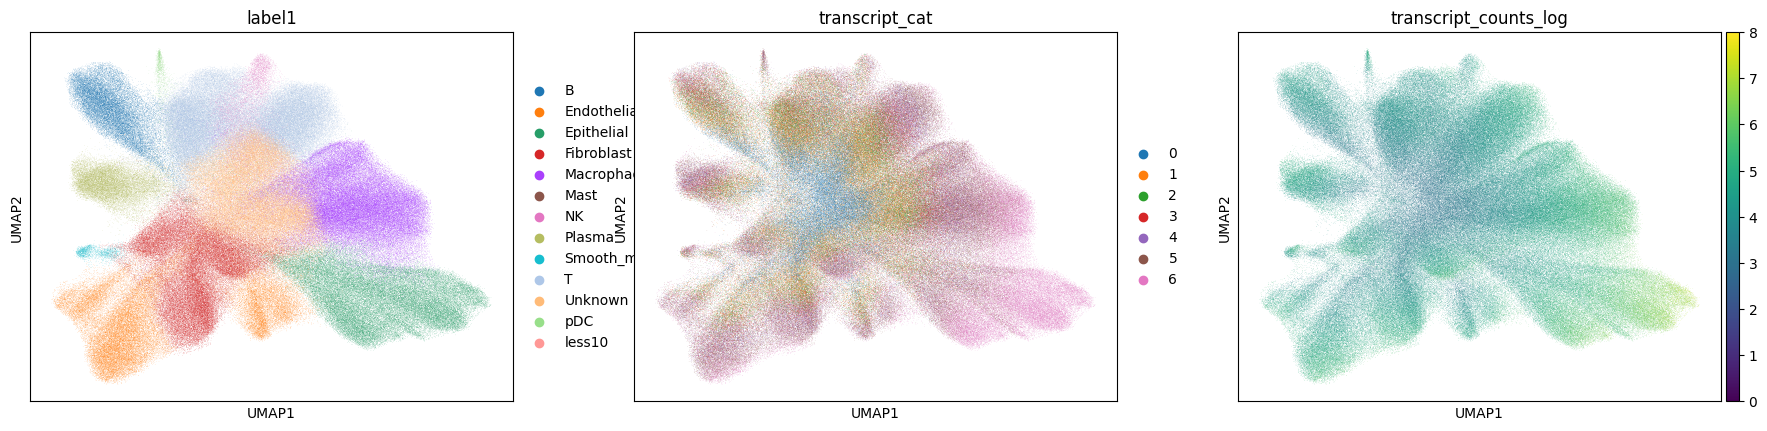

In [9]:
# Checking that clustering is not driven by number of transcripts for cells
sc.pl.umap(sdata.tables['table_cells'], neighbors_key='pca_n10_pcs16',
           color=['label1', 'transcript_cat', 'transcript_counts_log'])

In [10]:
# Put table_cells as annotating cell_boundaries

sdata["table_cells"].obs["region"] = "cell_boundaries"
sdata.tables["table_cells"].obs['region'] = sdata.tables["table_cells"].obs['region'].astype('category')
sdata.set_table_annotates_spatialelement(table_name="table_cells", region="cell_boundaries", region_key="region", instance_key="cell_id")

region, region_key, instance_key = get_table_keys(sdata["table_cells"])
print(region, region_key, instance_key)

cell_boundaries region cell_id


In [ ]:
# Save on disk
sdata_final_path = get_full_path("STHELAR_HistoST", "sdata_final", f"sdata_{slide_id}.zarr", as_str=True)
sdata.write(sdata_final_path)